In [7]:
import pandas as pd
from sqlalchemy import create_engine

sunucu     = "localhost"
veritabani = "Brazilian_E-Commerce_Public"
surucu     = "ODBC Driver 17 for SQL Server"

engine = create_engine(
    f"mssql+pyodbc://@{sunucu}/{veritabani}"
    f"?driver={surucu.replace(' ', '+')}&trusted_connection=yes&TrustServerCertificate=yes"
)

df = pd.read_sql("SELECT TOP 5 * FROM dbo.vw_order_analysis", engine)
print(df)

                           order_id                       customer_id  \
0  00054e8431b9d7675808bcb819fb4a32  32e2e6ab09e778d99bf2e0ecd4898718   
1  001e7ba991be1b19605ca0316e7130f9  b6a1445ee505f3a95c827e7a5188ad02   
2  0020262c8a370bd5a174ea6a2a267321  9ec353f970bdf785f6568724d9ea19aa   
3  002c9def9c9b951b1bec6d50753c9891  06cf02bf583b05fd91bc8eec0f1b4c3f   
4  002f16b7bc4530031b7d90f791b12d8a  1eeffe21744883fbf61fbf138dbb8eee   

                 customer_unique_id customer_state order_status  \
0  635d9ac1680f03288e72ada3a1035803             SP    delivered   
1  100bf2da12cc1fd1b556507aa87bf3a1             MS    delivered   
2  484689f7961df6e755f6373221aff64d             PR    delivered   
3  6bcc1cd0c7f8bffa6f67a6a1fbef5782             SP    delivered   
4  eb859d4b5ab54b643d2c0cedaca0c9fb             SP    delivered   

          purchase_ts purchase_month  is_delivered  delivery_days  delay_days  \
0 2017-12-10 11:53:48     2017-12-01             1              8         -17

In [9]:
df = pd.read_sql("SELECT * FROM dbo.vw_order_analysis", engine)

print("Satır sayısı:", len(df))
print("Teslim edilen:", int(df["is_delivered"].sum()))
print("Puanı olan:", int(df["review_score"].notna().sum()))

Satır sayısı: 99441
Teslim edilen: 96470
Puanı olan: 98673


In [11]:
from scipy import stats

d = df[(df["is_delivered"] == 1) & (df["review_score"].notna())].copy()
d["purchase_month"] = pd.to_datetime(d["purchase_month"])
d = d[(d["purchase_month"] >= "2017-02-01") & (d["purchase_month"] <= "2018-08-01")]

aylik = d.groupby("purchase_month").agg(
    siparis=("order_id", "count"),
    gecikme_orani=("is_late", lambda s: round(100 * s.mean(), 2)),
    ort_puan=("review_score", lambda s: round(s.mean(), 2)),
).reset_index()

print(aylik)

r, p = stats.pearsonr(aylik["gecikme_orani"], aylik["ort_puan"])
rho, p2 = stats.spearmanr(aylik["gecikme_orani"], aylik["ort_puan"])
print(f"\nAy sayısı: {len(aylik)}")
print(f"Pearson r = {r:.2f} (p = {p:.4f})")
print(f"Spearman rho = {rho:.2f} (p = {p2:.4f})")

   purchase_month  siparis  gecikme_orani  ort_puan
0      2017-02-01     1643           2.56      4.20
1      2017-03-01     2527           4.47      4.19
2      2017-04-01     2290           6.42      4.14
3      2017-05-01     3517           2.81      4.24
4      2017-06-01     3111           2.96      4.22
5      2017-07-01     3842           2.73      4.26
6      2017-08-01     4165           2.91      4.31
7      2017-09-01     4118           4.30      4.27
8      2017-10-01     4446           4.03      4.20
9      2017-11-01     7237          12.26      3.99
10     2017-12-01     5461           7.34      4.09
11     2018-01-01     7013           5.65      4.11
12     2018-02-01     6507          14.02      3.88
13     2018-03-01     6948          18.65      3.81
14     2018-04-01     6752           4.40      4.21
15     2018-05-01     6722           6.50      4.24
16     2018-06-01     6072           1.17      4.31
17     2018-07-01     6118           3.27      4.32
18     2018-

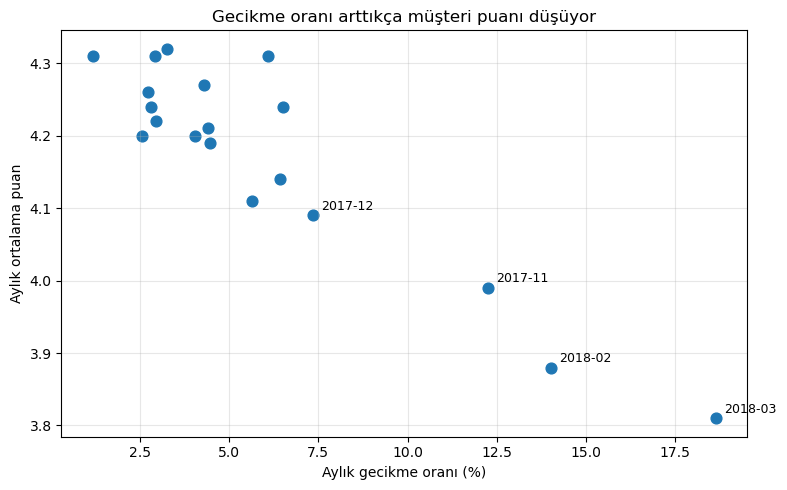

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(aylik["gecikme_orani"], aylik["ort_puan"], s=60, color="#1f77b4")

for _, satir in aylik.iterrows():
    ay = satir["purchase_month"].strftime("%Y-%m")
    if satir["gecikme_orani"] > 7 or satir["ort_puan"] < 4.0:
        ax.annotate(ay, (satir["gecikme_orani"], satir["ort_puan"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.set_xlabel("Aylık gecikme oranı (%)")
ax.set_ylabel("Aylık ortalama puan")
ax.set_title("Gecikme oranı arttıkça müşteri puanı düşüyor")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gecikme_puan_korelasyon.png", dpi=150)
plt.show()

In [19]:
tum = df[(df["is_delivered"] == 1) & (df["review_score"].notna())].copy()

zamaninda = tum[tum["is_late"] == 0]["review_score"]
gec       = tum[tum["is_late"] == 1]["review_score"]

print("Zamanında:", len(zamaninda), "sipariş, ort. puan", round(zamaninda.mean(), 2))
print("Geç      :", len(gec),       "sipariş, ort. puan", round(gec.mean(), 2))

u, p = stats.mannwhitneyu(zamaninda, gec, alternative="greater")
print(f"\nMann-Whitney U p-değeri: {p:.2e}")

dusuk_z = (zamaninda <= 2).mean() * 100
dusuk_g = (gec <= 2).mean() * 100
print(f"Düşük puan (1-2 yıldız) oranı: zamanında %{dusuk_z:.1f}, geç %{dusuk_g:.1f}")

Zamanında: 89443 sipariş, ort. puan 4.29
Geç      : 6381 sipariş, ort. puan 2.27

Mann-Whitney U p-değeri: 0.00e+00
Düşük puan (1-2 yıldız) oranı: zamanında %9.3, geç %62.4
